In [ ]:

import kagglehub
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download dataset
path = kagglehub.dataset_download(
    "camnugent/california-housing-prices"
)

print("Dataset path:", path)

# Find CSV file
csv_files = glob.glob(path + "/**/*.csv", recursive=True)

df = pd.read_csv(csv_files[0])

# Set plot style
sns.set_style("whitegrid")

print("Dataset loaded successfully!")


Using Colab cache for faster access to the 'california-housing-prices' dataset.
Dataset path: /kaggle/input/california-housing-prices
Dataset loaded successfully!


In [ ]:

print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY



Last 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [ ]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)


Number of rows: 20640
Number of columns: 10
Dataset shape: (20640, 10)


In [ ]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Missing values in each column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total missing values:
207


In [ ]:

print("Number of duplicate rows:",
      df.duplicated().sum())


Number of duplicate rows: 0


In [ ]:

print("Statistical Summary:")
display(df.describe())

print("\nCategorical Summary:")
display(df.describe(include='object'))


Statistical Summary:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000



Categorical Summary:


,ocean_proximity
count,20640
unique,5
top,<1H OCEAN
freq,9136


In [ ]:

numerical_cols = df.select_dtypes(
    include=np.number
).columns

categorical_cols = df.select_dtypes(
    include='object'
).columns

print("Numerical Columns:")
print(numerical_cols.tolist())

print("\nCategorical Columns:")
print(categorical_cols.tolist())


Numerical Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']

Categorical Columns:
['ocean_proximity']


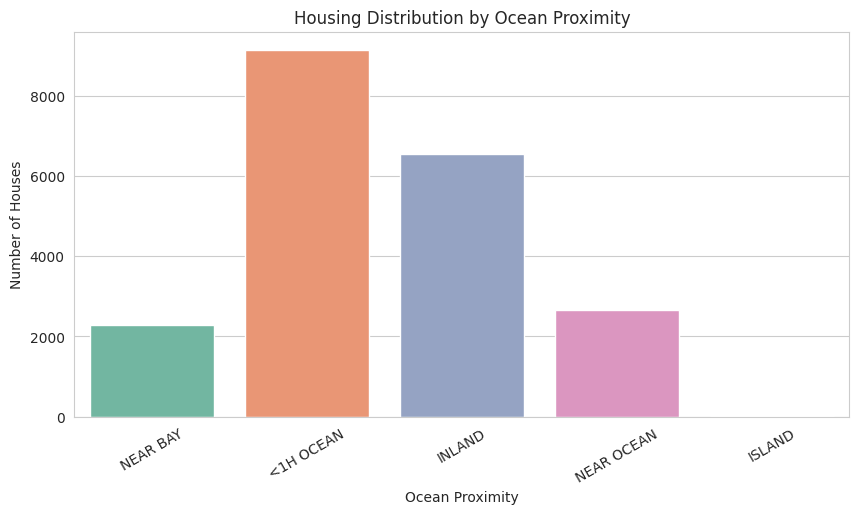

In [ ]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='ocean_proximity',
    hue='ocean_proximity',
    legend=False,
    palette='Set2'
)

plt.title("Housing Distribution by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Number of Houses")
plt.xticks(rotation=30)

plt.show()


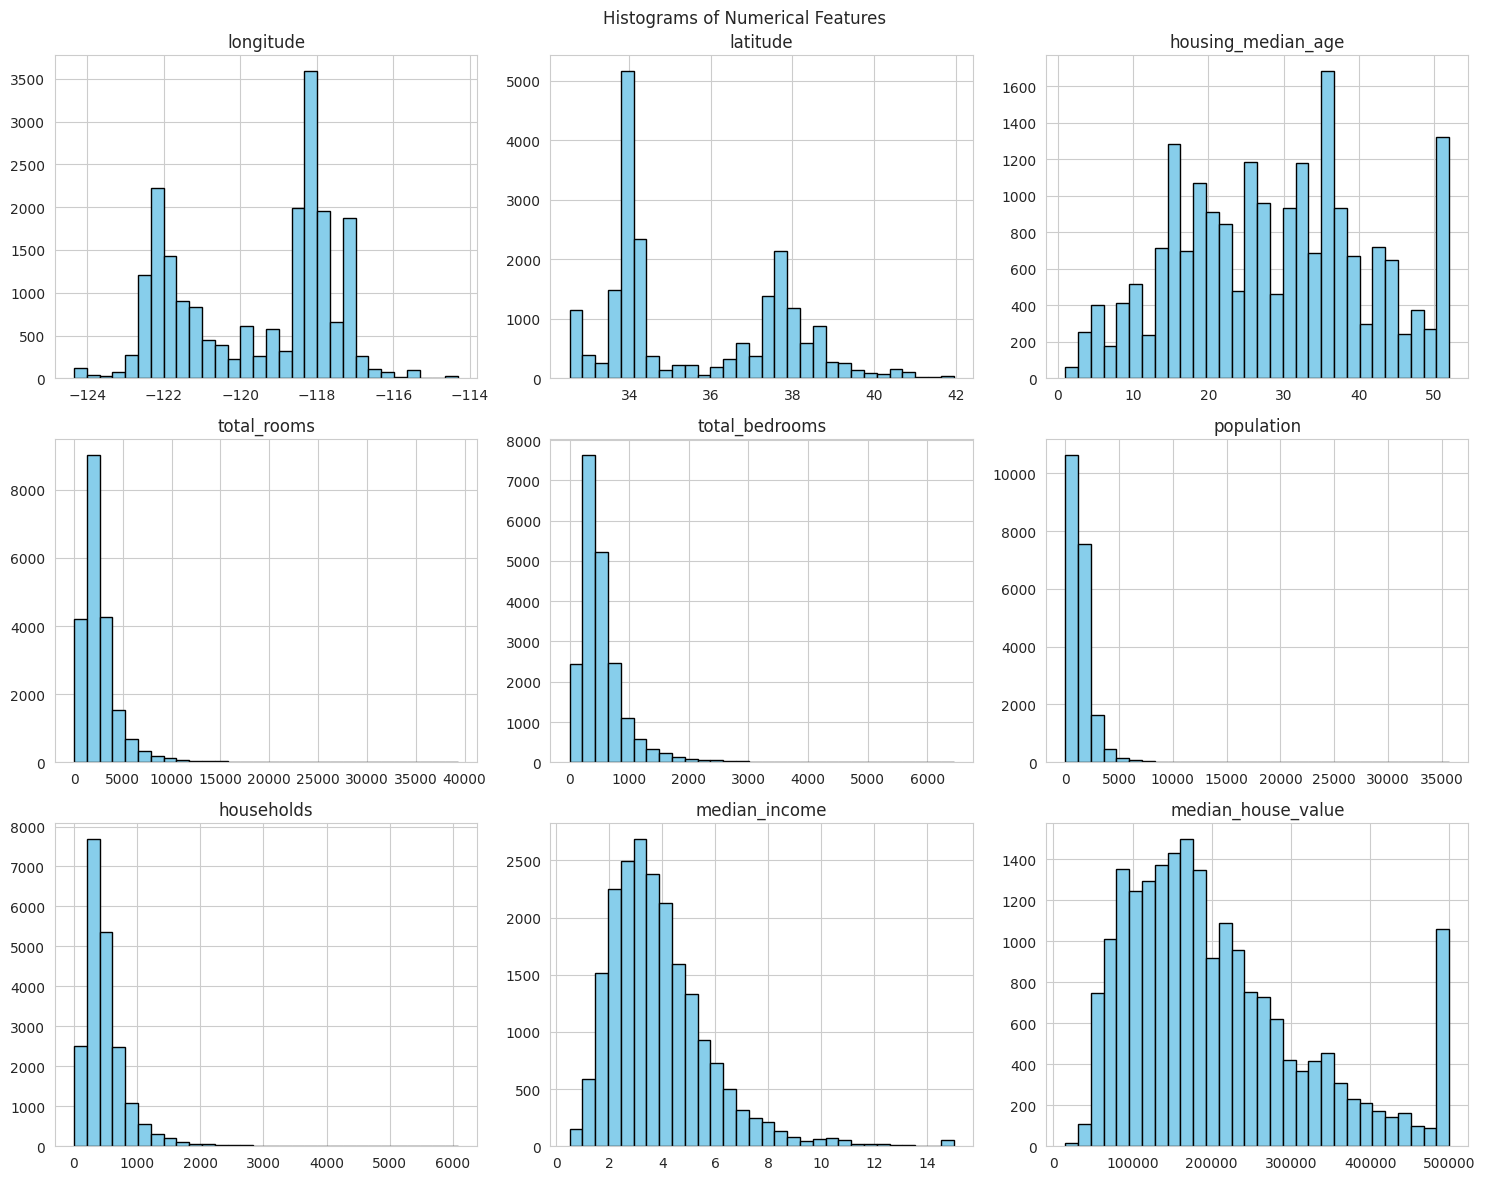

In [ ]:

df[numerical_cols].hist(
    figsize=(15, 12),
    bins=30,
    color='skyblue',
    edgecolor='black'
)

plt.suptitle("Histograms of Numerical Features")
plt.tight_layout()
plt.show()


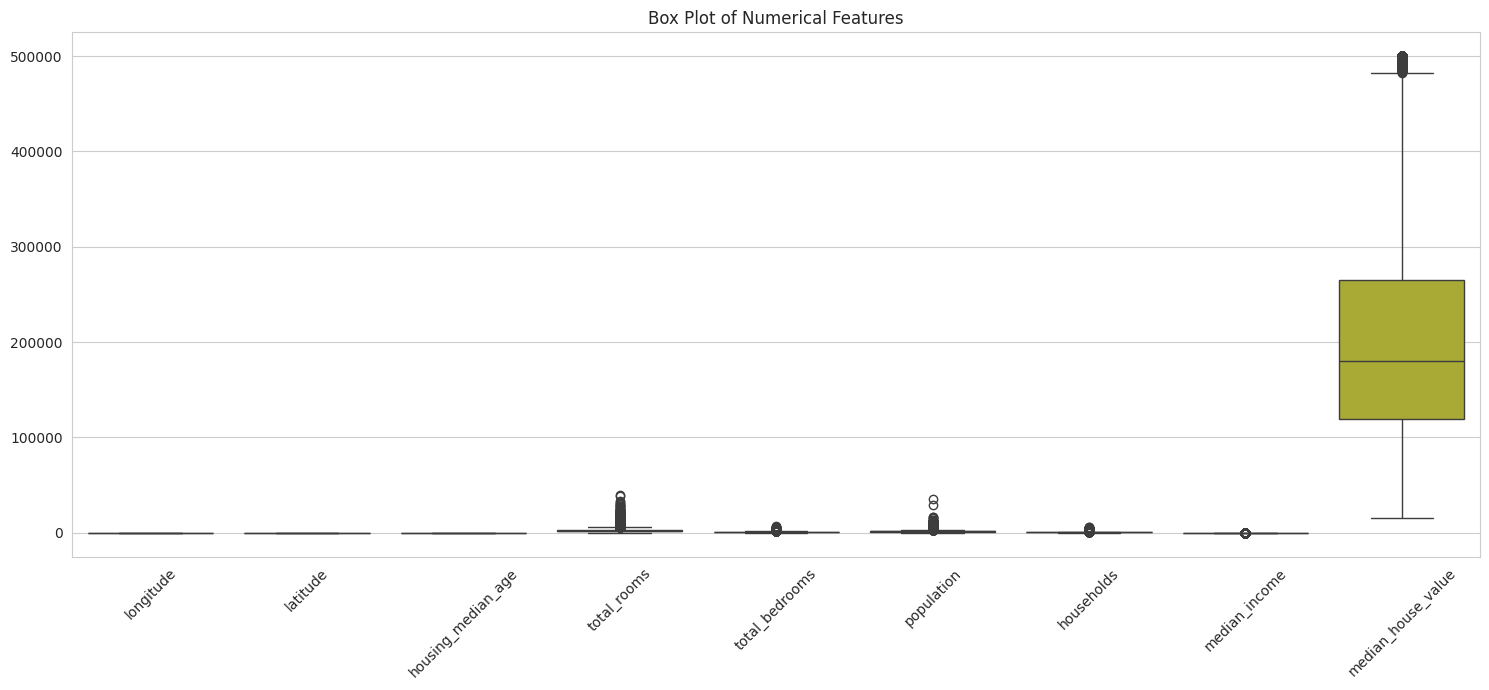

In [ ]:

plt.figure(figsize=(15, 7))

sns.boxplot(data=df[numerical_cols])

plt.title("Box Plot of Numerical Features")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


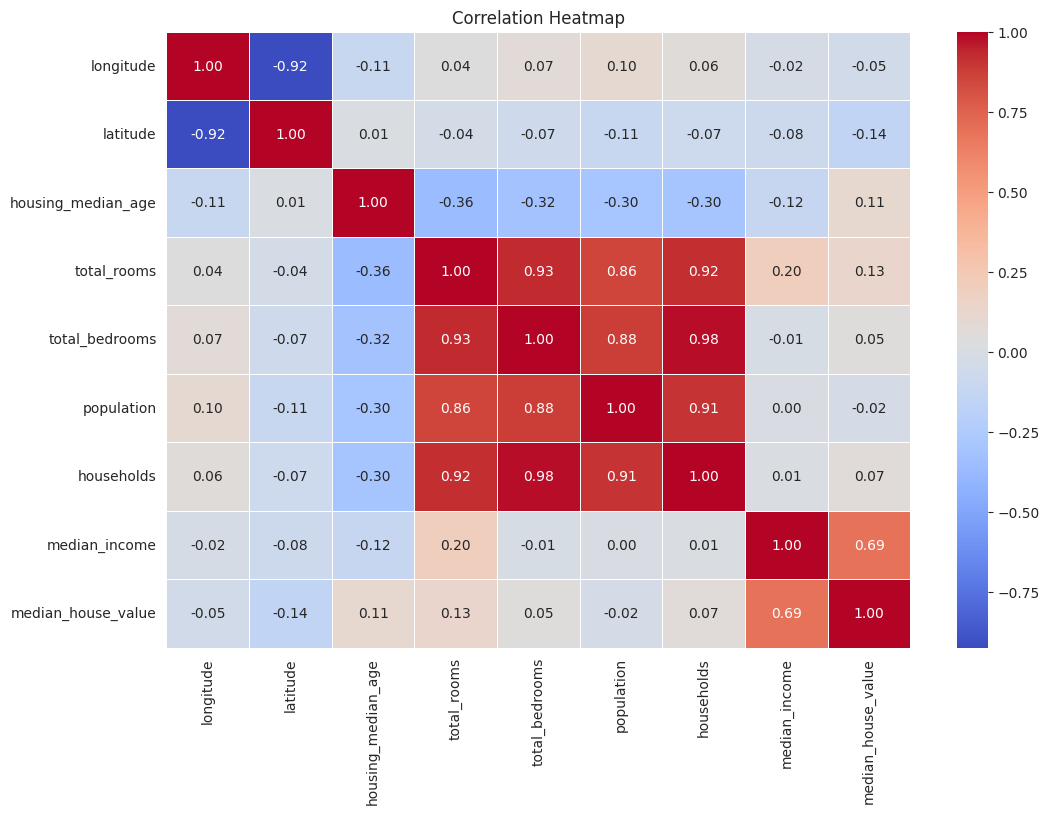

In [ ]:

plt.figure(figsize=(12, 8))

correlation = df[numerical_cols].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()


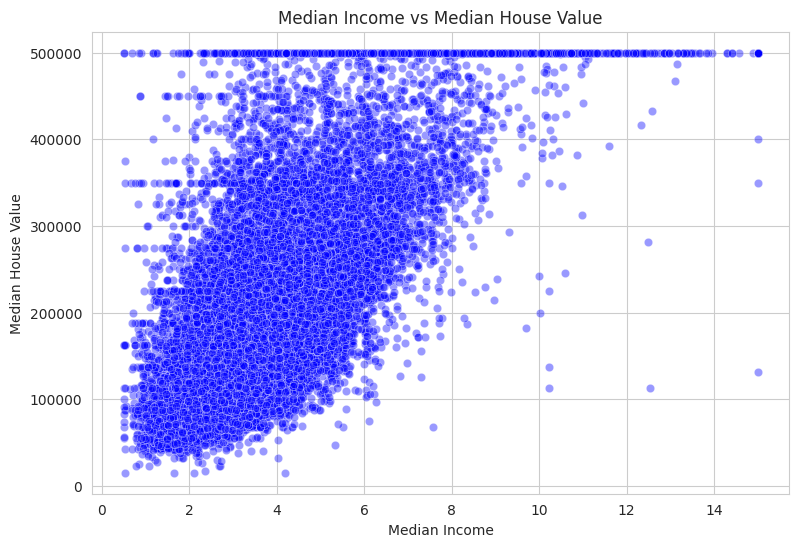

In [ ]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='median_income',
    y='median_house_value',
    alpha=0.4,
    color='blue'
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()


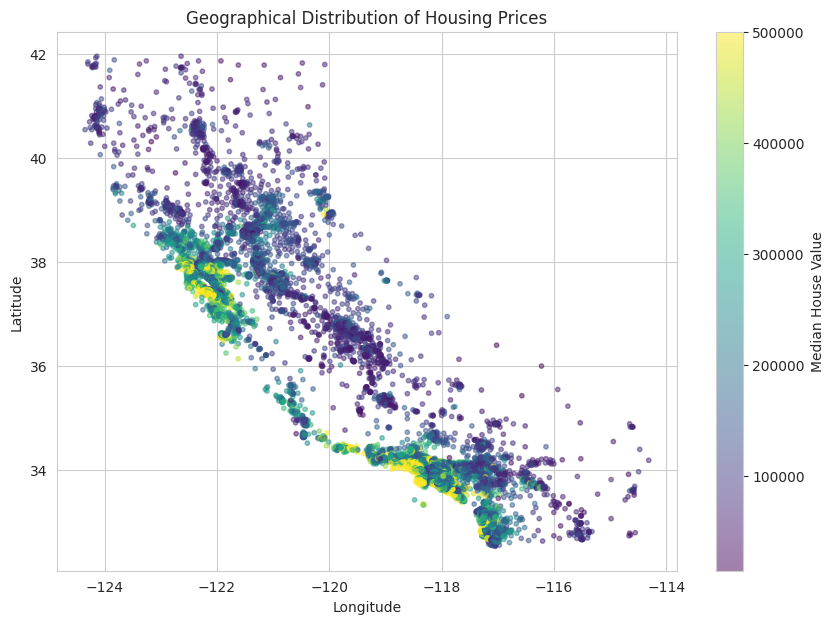

In [ ]:

plt.figure(figsize=(10, 7))

plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['median_house_value'],
    cmap='viridis',
    alpha=0.5,
    s=10
)

plt.colorbar(label='Median House Value')

plt.title("Geographical Distribution of Housing Prices")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()


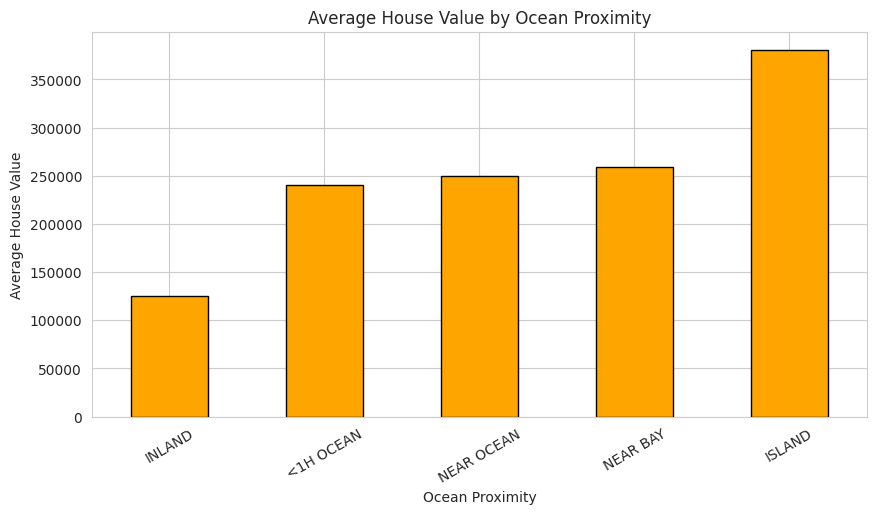

In [ ]:

plt.figure(figsize=(10, 5))

avg_price = df.groupby(
    'ocean_proximity',
    observed=True
)['median_house_value'].mean().sort_values()

avg_price.plot(
    kind='bar',
    color='orange',
    edgecolor='black'
)

plt.title("Average House Value by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Average House Value")
plt.xticks(rotation=30)

plt.show()


In [ ]:

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")


longitude : 0 outliers
latitude : 0 outliers
housing_median_age : 0 outliers
total_rooms : 1287 outliers
total_bedrooms : 1271 outliers
population : 1196 outliers
households : 1220 outliers
median_income : 681 outliers
median_house_value : 1071 outliers


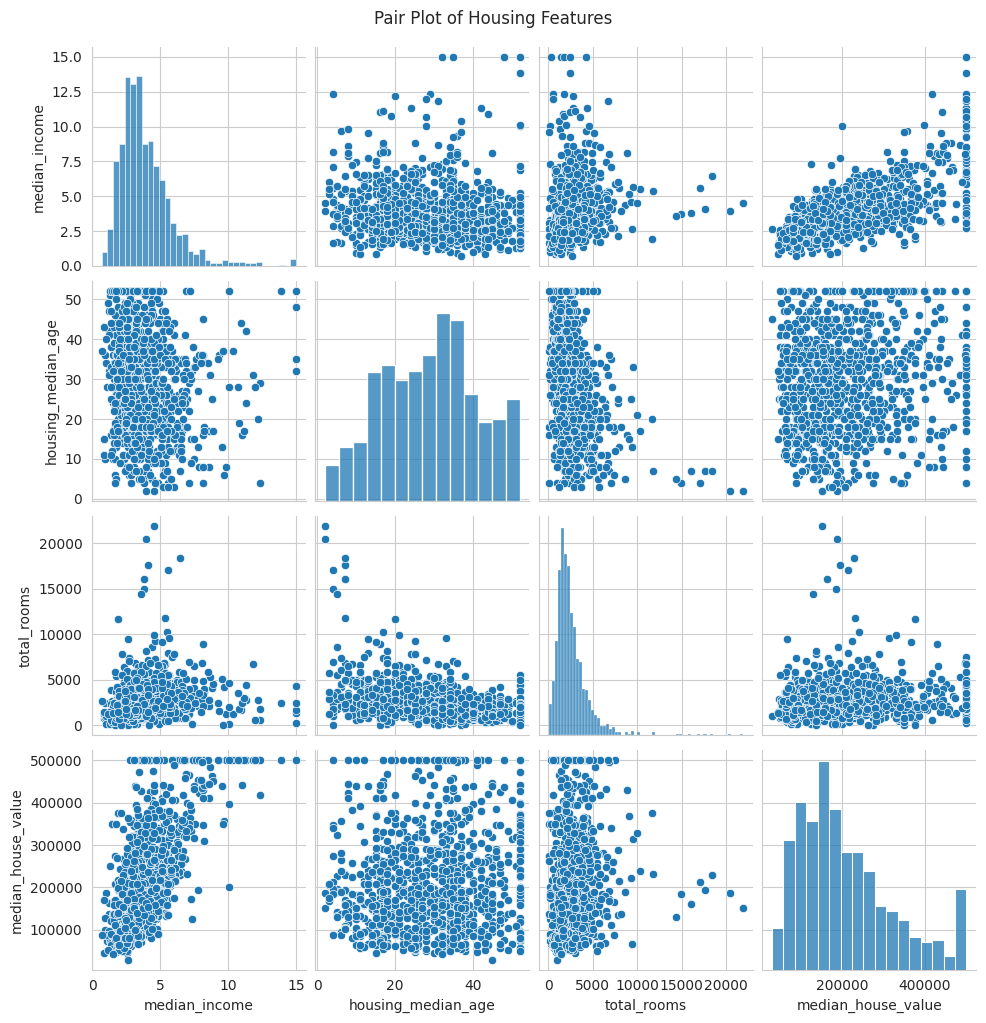

In [ ]:

selected_cols = [
    'median_income',
    'housing_median_age',
    'total_rooms',
    'median_house_value'
]

sns.pairplot(
    df[selected_cols].sample(
        n=min(1000, len(df)),
        random_state=42
    ),
    diag_kind='hist'
)

plt.suptitle("Pair Plot of Housing Features", y=1.02)
plt.show()


In [ ]:
# Select numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

# Create scaler
minmax_scaler = MinMaxScaler()

# Create a copy of dataset
df_minmax = df.copy()

# Apply Min-Max normalization
df_minmax[numerical_cols] = minmax_scaler.fit_transform(
    df[numerical_cols]
)

print("Min-Max Normalized Dataset:")
print(df_minmax.head())

print("\nMinimum values:")
print(df_minmax[numerical_cols].min())

print("\nMaximum values:")
print(df_minmax[numerical_cols].max())


Min-Max Normalized Dataset:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0   0.211155  0.567481            0.784314     0.022331        0.019863   
1   0.212151  0.565356            0.392157     0.180503        0.171477   
2   0.210159  0.564293            1.000000     0.037260        0.029330   
3   0.209163  0.564293            1.000000     0.032352        0.036313   
4   0.209163  0.564293            1.000000     0.041330        0.043296   

   population  households  median_income  median_house_value ocean_proximity  
0    0.008941    0.020556       0.539668            0.902266        NEAR BAY  
1    0.067210    0.186976       0.538027            0.708247        NEAR BAY  
2    0.013818    0.028943       0.466028            0.695051        NEAR BAY  
3    0.015555    0.035849       0.354699            0.672783        NEAR BAY  
4    0.015752    0.042427       0.230776            0.674638        NEAR BAY  

Minimum values:
longitude             0.0
lati

In [ ]:



# Create scaler
zscore_scaler = StandardScaler()

# Create a copy of dataset
df_zscore = df.copy()

# Apply Z-score standardization
df_zscore[numerical_cols] = zscore_scaler.fit_transform(
    df[numerical_cols]
)

print("Z-score Standardized Dataset:")
print(df_zscore.head())

print("\nMean values:")
print(df_zscore[numerical_cols].mean())

print("\nStandard deviation:")
print(df_zscore[numerical_cols].std())


Z-score Standardized Dataset:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0  -1.327835  1.052548            0.982143    -0.804819       -0.970325   
1  -1.322844  1.043185           -0.607019     2.045890        1.348276   
2  -1.332827  1.038503            1.856182    -0.535746       -0.825561   
3  -1.337818  1.038503            1.856182    -0.624215       -0.718768   
4  -1.337818  1.038503            1.856182    -0.462404       -0.611974   

   population  households  median_income  median_house_value ocean_proximity  
0   -0.974429   -0.977033       2.344766            2.129631        NEAR BAY  
1    0.861439    1.669961       2.332238            1.314156        NEAR BAY  
2   -0.820777   -0.843637       1.782699            1.258693        NEAR BAY  
3   -0.766028   -0.733781       0.932968            1.165100        NEAR BAY  
4   -0.759847   -0.629157      -0.012881            1.172900        NEAR BAY  

Mean values:
longitude            -8.603626e

In [ ]:

print("Original Data:")
print(df[numerical_cols].head())

print("\nMin-Max Normalized Data:")
print(df_minmax[numerical_cols].head())

print("\nZ-score Standardized Data:")
print(df_zscore[numerical_cols].head())


Original Data:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value  
0       322.0       126.0         8.3252            452600.0  
1      2401.0      1138.0         8.3014            358500.0  
2       496.0       177.0         7.2574            352100.0  
3       558.0       219.0         5.6431            341300.0  
4       565.0       259.0         3.8462            342200.0  

Min-Max Normalized Data:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0   0.211155  0.567481            0.784314     0.022331

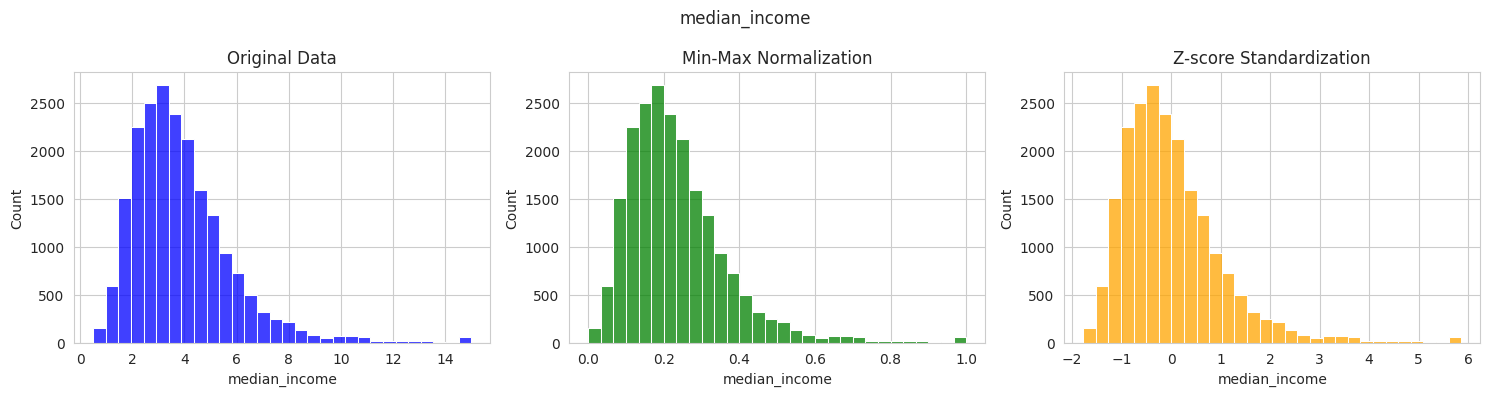

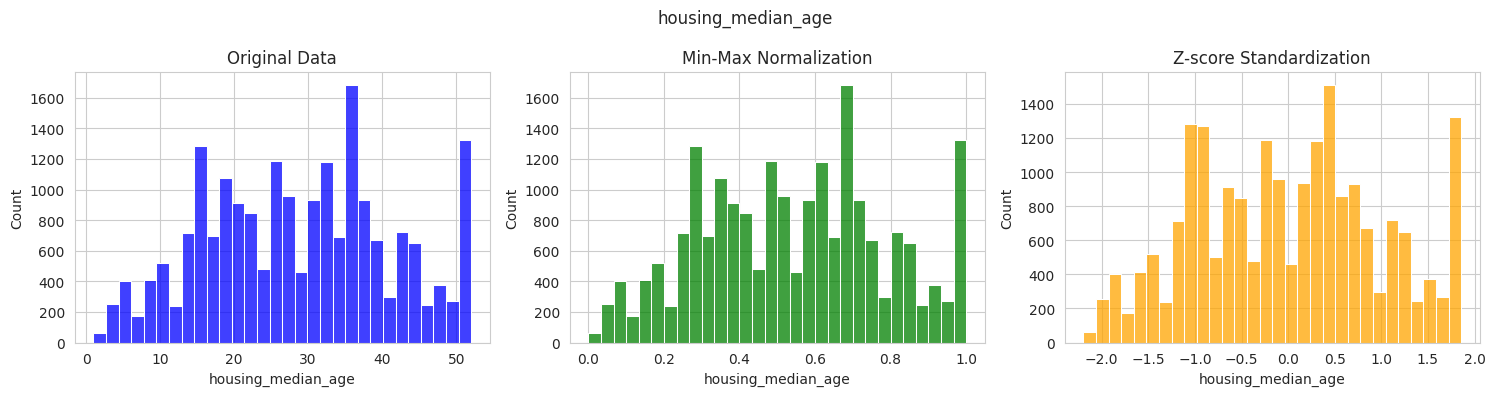

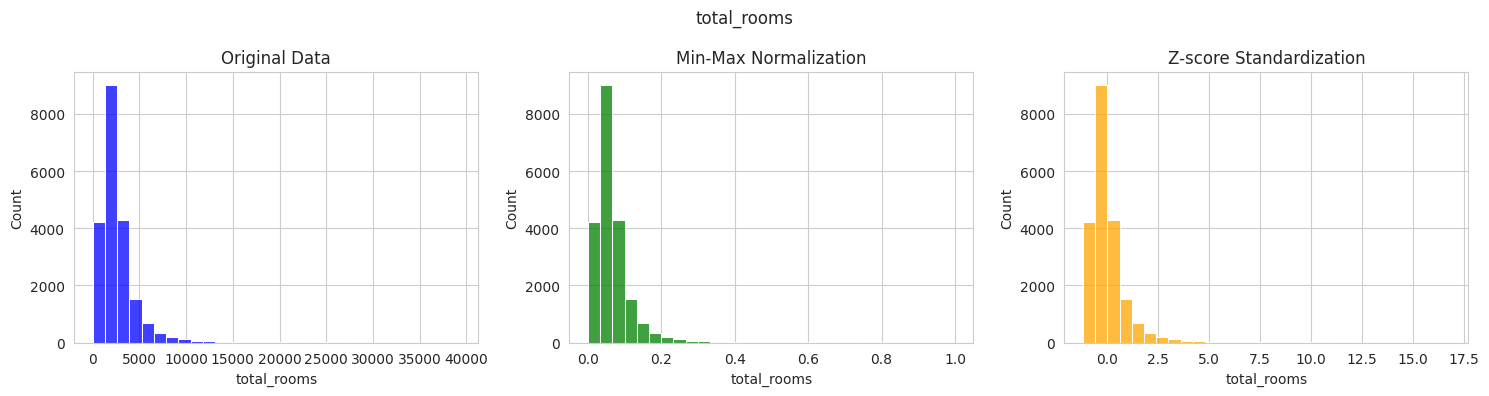

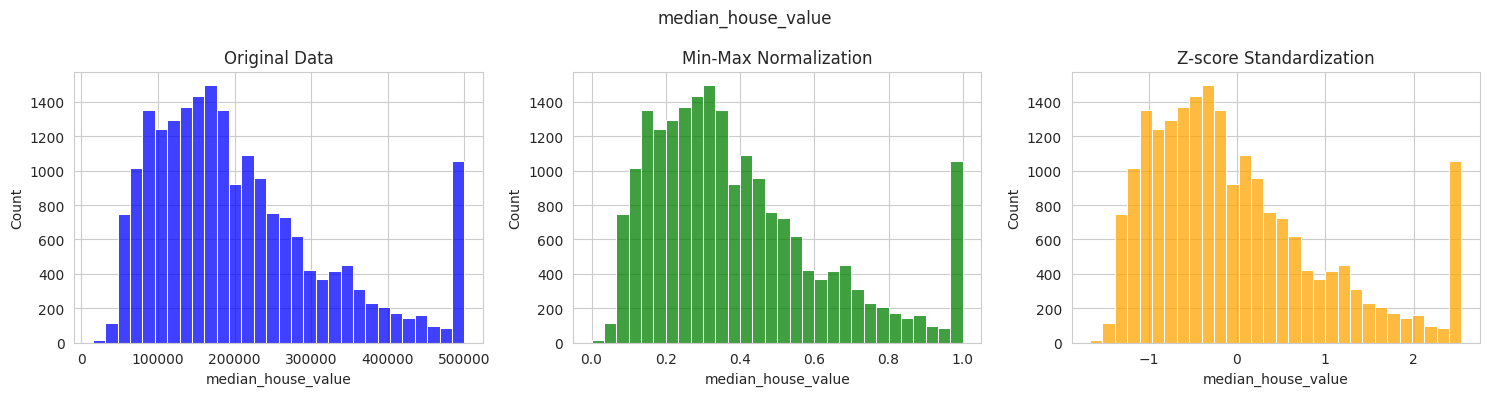

In [ ]:
features = ['median_income', 'housing_median_age',
            'total_rooms', 'median_house_value']

for col in features:
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    sns.histplot(df[col], bins=30, color='blue')
    plt.title("Original Data")

    plt.subplot(1, 3, 2)
    sns.histplot(df_minmax[col], bins=30, color='green')
    plt.title("Min-Max Normalization")

    plt.subplot(1, 3, 3)
    sns.histplot(df_zscore[col], bins=30, color='orange')
    plt.title("Z-score Standardization")

    plt.suptitle(col)
    plt.tight_layout()
    plt.show()

In [ ]:
df.to_csv('cleaned_dataset.csv', index = False)